In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Stochastic and Minibatch Gradient Descent

In that section, every parameter update used the exact gradient of the objective, which requires evaluating the loss across the entire training set on every step. In deep learning, full-batch gradient descent is computationally prohibitive: training ResNet-50 on the $1.28$ million images of ImageNet for $90$ epochs with minibatches of $256$ images takes $450{,}000$ updates [@Goyal.Dollar.Girshick.ea.2017], whereas $450{,}000$ full-batch steps would require $450{,}000$ complete passes over the dataset—$5{,}000$ times as much computation.

Instead, **stochastic gradient descent** (SGD) estimates the gradient from a single randomly sampled example or a small **minibatch** of $b$ examples (that section). This estimate is unbiased, and its variance decreases as $1/b$, but the sampling noise fundamentally alters the late-stage behavior of optimization: with a constant learning rate $\eta$, iterates do not converge to a point minimum but fluctuate inside a stationary **noise ball**.

In this section, we combine gradient noise with uneven curvature. Using the two-dimensional valley of that section, we derive the stationary variance of constant-step SGD along each curvature direction, test the resulting excess-loss prediction on a real regression dataset, examine how sampling without replacement and hardware parallelism shape minibatch selection, and motivate learning-rate decay (that section) and momentum (that section).

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

## Stochastic Gradient Descent

### Sampled Gradients and the Valley

For an empirical risk $f(\mathbf{x}) = \frac{1}{n} \sum_{i=1}^n f_i(\mathbf{x})$ over $n$ training examples, the exact gradient is the average of the per-example gradients:

$$\nabla f(\mathbf{x}) = \frac{1}{n} \sum_{i = 1}^n \nabla f_i(\mathbf{x}).$$

Single-example SGD draws an index $i \in \{1, \ldots, n\}$ uniformly at random at each step and updates

$$\mathbf{x} \leftarrow \mathbf{x} - \eta \nabla f_i(\mathbf{x}).$$

Because $\mathbb{E}_i[\nabla f_i(\mathbf{x})] = \nabla f(\mathbf{x})$, the stochastic gradient can be decomposed as $\nabla f_i(\mathbf{x}) = \nabla f(\mathbf{x}) + \boldsymbol{\xi}$, where the gradient noise $\boldsymbol{\xi}$ has mean zero.

To see how $\boldsymbol{\xi}$ interacts with curvature, we first define `sgd_2d` to add independent zero-mean, unit-variance Gaussian noise to both gradient coordinates:

In [2]:
def sgd_2d(x1, x2, s1, s2, f_grad, eta, rng):
    g1, g2 = f_grad(x1, x2)
    n1, n2 = rng.normal(size=2)  # Unit-variance gradient noise
    return x1 - eta * (g1 + n1), x2 - eta * (g2 + n2), 0, 0

We then run $300$ steps of `sgd_2d` on the valley $f(\mathbf{x}) = 0.1 x_1^2 + 2 x_2^2$ (that section) at $\eta = 0.1$ from $(-5, -2)$:

step 300, x1: -0.371201, x2: -0.077858


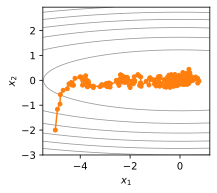

In [3]:
rng = np.random.default_rng()
trace = d2l.train_2d(sgd_2d, d2l.valley_grad, steps=300, eta=0.1, rng=rng)
d2l.show_trace_2d(d2l.f_valley, trace)

During the first $\sim 100$ steps, the deterministic gradient dominates and the iterate approaches the origin. Once near the origin, $\|\nabla f(\mathbf{x})\|$ becomes small while the noise amplitude remains constant, trapping the iterate in an elongated cloud stretched along the flat axis $x_1$.

### The Noise Ball

We can compute the dimensions of this cloud analytically. Along an eigenvector with curvature $\lambda > 0$ and independent zero-mean gradient noise $\xi_t$ of variance $\sigma^2$, a single SGD step evolves according to

$$x_{t+1} = x_t - \eta\, (\lambda x_t + \xi_t) = (1 - \eta\lambda)\, x_t - \eta\, \xi_t.$$

Squaring both sides and taking expectations (using $\mathbb{E}[x_t \xi_t] = 0$) gives the second-moment recursion

$$\mathbb{E}\big[x_{t+1}^2\big] = (1 - \eta\lambda)^2\, \mathbb{E}\big[x_t^2\big] + \eta^2 \sigma^2.$$

For any stable step size $0 < \eta < 2/\lambda$, the mean $\mathbb{E}[x_t]$ decays to zero and the second moment converges to the stationary variance where deterministic contraction balances noise injection, $\mathbb{E}[x_\infty^2] = (1 - \eta\lambda)^2 \mathbb{E}[x_\infty^2] + \eta^2 \sigma^2$:

$$\mathbb{E}\big[x_\infty^2\big] = \frac{\eta\, \sigma^2}{\lambda\, (2 - \eta\lambda)} \approx \frac{\eta\, \sigma^2}{2\lambda} \quad \textrm{for } \eta\lambda \ll 1.$$

Equation the equation characterizes the **noise ball** (that section derives the full finite-time trajectory):

1. **Stability ceiling preserved:** As $\eta \to 2/\lambda$, the denominator $(2 - \eta\lambda) \to 0$ and the variance diverges.
2. **Inverse curvature scaling:** The stationary variance is inversely proportional to curvature $\lambda$. On the valley at $\eta = 0.1$ with $\sigma^2 = 1$, the stationary variance is $0.1 / (0.2 \times 1.98) \approx 0.2525$ along the flat coordinate $x_1$ ($\text{std} \approx 0.50$) and $0.1 / (4 \times 1.6) \approx 0.0156$ along the steep coordinate $x_2$ ($\text{std} \approx 0.125$). Flat directions suffer twice: they converge slowly during the transient phase and fluctuate widely at steady state.
3. **Linear step-size scaling:** For $\eta\lambda \ll 1$, halving the learning rate $\eta$ halves the stationary variance along every direction, as confirmed by simulating $10{,}000$ independent trajectories:

In [4]:
def noise_ball(eta, lam, num_runs=10000, num_steps=2000):
    """Variance of SGD iterates on sum(lam * x**2 / 2) with unit noise."""
    rng = np.random.default_rng()
    x = np.zeros((num_runs, len(lam)))
    for _ in range(num_steps):
        x = x - eta * (lam * x + rng.normal(size=x.shape))
    return x.var(axis=0)

lam = np.array(d2l.VALLEY_CURVATURES)  # Curvatures of the valley
for eta in (0.1, 0.05):
    print(f'eta={eta}: measured {noise_ball(eta, lam).round(4)}, '
          f'predicted {(eta / (lam * (2 - eta * lam))).round(4)}')

eta=0.1: measured [0.2544 0.0157], predicted [0.2525 0.0156]


eta=0.05: measured [0.1275 0.007 ], predicted [0.1256 0.0069]


### Decreasing Learning Rates

Constant-step SGD faces a fundamental trade-off: a smaller learning rate $\eta$ shrinks the noise ball $\propto \eta$ but slows down initial convergence by reducing the per-step contraction rate $\eta\lambda$. Eliminating the noise floor requires decaying the learning rate $\eta_t$ over time. @Robbins.Monro.1951 established that for smooth, strongly convex objectives with bounded gradient variance, SGD converges to the exact minimizer if the step sizes satisfy

$$\sum_{t=1}^{\infty} \eta_t = \infty \qquad \textrm{and} \qquad \sum_{t=1}^{\infty} \eta_t^2 < \infty.$$

The first condition ensures that the cumulative step budget is infinite so the iterate can reach the optimum from any initialization, while the second ensures that the cumulative injected noise variance $\propto \sum_t \eta_t^2$ remains finite. Polynomial schedules such as $\eta_t = c / (t + t_0)$ with $c > 1/(2\lambda_{\min})$ satisfy both conditions and reduce the expected squared error at rate $\mathbb{E}[\|\mathbf{x}_t - \mathbf{x}^\star\|^2] = O(1/t)$ (that section; Exercise 2). On a fixed training budget of $T$ steps, practical deep learning replaces asymptotic $1/t$ schedules with cosine, linear, or warmup–stable–decay schedules (that section).

## Minibatches

### Gradient Variance and Batch Size

Instead of a single example, minibatch SGD averages the gradient over a random subset $\mathcal{B}_t$ of $b$ examples:

$$\mathbf{g}_t = \frac{1}{b} \sum_{i \in \mathcal{B}_t} \nabla f_i(\mathbf{x}_t).$$

Let $\boldsymbol{\Sigma}(\mathbf{x}) = \mathbb{E}_i\big[(\nabla f_i(\mathbf{x}) - \nabla f(\mathbf{x}))(\nabla f_i(\mathbf{x}) - \nabla f(\mathbf{x}))^\top\big]$ denote the per-example gradient covariance matrix, whose trace $\operatorname{tr}\boldsymbol{\Sigma} = \mathbb{E}_i\|\nabla f_i(\mathbf{x}) - \nabla f(\mathbf{x})\|^2$ is the total per-example gradient variance. For $b$ examples drawn independently with replacement, averaging divides the covariance by $b$:

$$\mathbb{E} \big\|\mathbf{g}_t - \nabla f(\mathbf{x}_t)\big\|^2 = \frac{\operatorname{tr} \boldsymbol{\Sigma}}{b}.$$

Substituting $\sigma^2 \leftarrow \sigma^2 / b$ into the equation gives the minibatch stationary variance along curvature $\lambda$:

$$\mathbb{E}\big[x_\infty^2\big] = \frac{\eta\, \sigma^2}{b\,\lambda\, (2 - \eta\lambda)} \approx \frac{\eta}{b} \cdot \frac{\sigma^2}{2\lambda} \quad \textrm{for } \eta\lambda \ll 1.$$

In the small-step regime $\eta\lambda \ll 1$, the learning rate and batch size govern the stationary noise ball solely through their ratio **$\eta / b$**: doubling the batch size $b$ has the same effect on the noise floor as halving the learning rate $\eta$.

### The Excess Loss on Data

How much does fluctuation inside the noise ball raise the training loss above its minimum $f(\mathbf{x}^\star)$? Along the $k$-th eigenvector of the Hessian $\mathbf{H}$ (with eigenvalue $\lambda_k$ and per-example gradient variance $\sigma_k^2$), a stationary displacement of variance $v_k \approx \frac{\eta \sigma_k^2}{2 \lambda_k b}$ contributes $\frac{1}{2}\lambda_k v_k$ to the expected quadratic loss:

$$\frac{1}{2} \lambda_k \left(\frac{\eta\, \sigma_k^2}{2 \lambda_k b}\right) = \frac{\eta\, \sigma_k^2}{4b}.$$

Notice that the curvature $\lambda_k$ cancels: flat directions fluctuate across a wider radius ($\propto 1/\lambda_k$), but a unit displacement along a flat direction raises the loss less ($\propto \lambda_k$). Summing across all $d$ orthogonal eigenvectors ($\sum_{k=1}^d \sigma_k^2 = \operatorname{tr}\boldsymbol{\Sigma}$) yields the stationary **excess loss**:

$$\mathbb{E}\big[f(\mathbf{x}_\infty)\big] - f(\mathbf{x}^\star) \approx \frac{\eta \operatorname{tr} \boldsymbol{\Sigma}(\mathbf{x}^\star)}{4b}.$$

We test the equation on the NASA airfoil self-noise regression dataset ($n = 1{,}500$ wind-tunnel measurements with $5$ standardized features and $1$ standardized sound-pressure target):

In [5]:

d2l.DATA_HUB['airfoil'] = (d2l.DATA_URL + 'airfoil_self_noise.dat',
                           '76e5be1548fd8222e5074cf0faae75edff8cf93f')


def get_airfoil(batch_size=10, n=1500):
    """Load the standardized airfoil self-noise data as minibatches."""
    data = np.genfromtxt(d2l.download('airfoil'),
                         dtype=np.float32, delimiter='\t')
    data = torch.from_numpy((data - data.mean(axis=0)) / data.std(axis=0))
    dataset = torch.utils.data.TensorDataset(
        *(t.to(d2l.try_gpu()) for t in (data[:n, :-1], data[:n, -1])))
    sampler = torch.utils.data.BatchSampler(  # Whole minibatches of indices
        torch.utils.data.RandomSampler(dataset), batch_size, drop_last=False)
    data_iter = torch.utils.data.DataLoader(dataset, sampler=sampler,
                                            batch_size=None)
    return data_iter, data.shape[1]-1

For linear regression with squared loss (representing the bias as a $6$th weight on a constant feature), we compute the exact Hessian $\mathbf{H} = \frac{1}{n}\mathbf{X}^\top\mathbf{X}$, the closed-form minimizer $\mathbf{w}^\star$, the largest curvature $L = \lambda_{\max}(\mathbf{H}) \approx 2.10$, and the per-example gradient variance $\operatorname{tr}\boldsymbol{\Sigma}(\mathbf{w}^\star) \approx 3.24$:

In [6]:
data_iter, num_features = get_airfoil(batch_size=1500)
X, y = map(d2l.numpy, next(iter(data_iter)))  # All 1,500 examples
X = np.hstack([X, np.ones((len(X), 1), np.float32)])  # Bias as a 6th weight
H = X.T @ X / len(X)  # Hessian of the loss
w_star = np.linalg.lstsq(X, y)[0]  # The minimizer, in closed form
G = X * (X @ w_star - y)[:, None]  # Per-example gradients at w_star
tr_Sigma = (G ** 2).sum(axis=1).mean()
print(f'L = {np.linalg.eigvalsh(H).max():.2f}, tr Sigma = {tr_Sigma:.2f}')

L = 2.10, tr Sigma = 3.24


To measure the empirical excess loss against this prediction, `sgd_runs` simulates `num_runs=400` vectorized minibatch SGD trajectories sampled with replacement, and `excess_loss` evaluates $\frac{1}{2}(\mathbf{w} - \mathbf{w}^\star)^\top \mathbf{H} (\mathbf{w} - \mathbf{w}^\star)$:

In [7]:
def sgd_runs(X, y, w, eta, b, num_steps, rng, num_runs=400):
    """Run minibatch SGD on the squared loss num_runs times from w, drawing
    examples with replacement; return every iterate, (steps, runs, d)."""
    W, trace = np.tile(w, (num_runs, 1)), []
    for idx in rng.integers(0, len(X), (num_steps, num_runs, b)):
        r = np.einsum('rbd,rd->rb', X[idx], W) - y[idx]  # Residuals
        W = W - eta / b * np.einsum('rbd,rb->rd', X[idx], r)
        trace.append(W)
    return np.array(trace)

def excess_loss(W, w_star, H):
    """f(w) - f(w_star) of the quadratic loss, for every w in the last axis."""
    D = W - w_star
    return 0.5 * np.einsum('...d,de,...e->...', D, H, D)

Starting at $\mathbf{w}^\star$ with batch size $b = 10$, we average `excess_loss` over the third epoch ($150$ steps) at $\eta \in \{0.05, 0.025\}$ and compare with $\eta\operatorname{tr}\boldsymbol{\Sigma}/(4b)$:

In [8]:
rng = np.random.default_rng()
for eta in (0.05, 0.025):  # b = 10, three epochs of 150 steps from w_star
    trace = sgd_runs(X, y, w_star, eta, 10, 450, rng)
    measured = excess_loss(trace[-150:], w_star, H).mean()  # The last epoch
    print(f'eta={eta}: excess loss {measured:.4f}, '
          f'predicted {eta * tr_Sigma / (4 * 10):.4f}')

eta=0.05: excess loss 0.0042, predicted 0.0041


eta=0.025: excess loss 0.0021, predicted 0.0020


At $b = 10$, the measured excess losses (about $0.004$ at $\eta = 0.05$ and $0.002$ at $\eta = 0.025$) closely match the prediction $\eta\operatorname{tr}\boldsymbol{\Sigma}/(4b)$. Notice what happens in the **interpolating regime**, where a model has enough capacity to fit every training example exactly so that $\nabla f_i(\mathbf{x}^\star) = \mathbf{0}$ for all $i$: in that limit, $\operatorname{tr}\boldsymbol{\Sigma}(\mathbf{x}^\star) = 0$, the noise ball vanishes as the iterate approaches $\mathbf{x}^\star$, and constant-step SGD converges geometrically to the exact minimizer. Overparameterized classifiers trained for many epochs approach this interpolating regime, whereas large language models trained for a single pass over massive corpora remain in the noise-limited regime where $\operatorname{tr}\boldsymbol{\Sigma}(\mathbf{x}^\star) > 0$.

### Sampling without Replacement

In practice, data loaders do not sample minibatches independently with replacement; instead, they randomly permute the dataset at the start of each epoch and partition it into disjoint minibatches of size $b$. Sampling $b$ distinct examples without replacement from a finite population of size $n$ introduces a negative correlation between per-example gradient errors (since $\sum_{i=1}^n (\nabla f_i(\mathbf{x}) - \nabla f(\mathbf{x})) = \mathbf{0}$), multiplying the minibatch gradient variance the equation by the finite-population correction factor (Exercise 3):

$$\mathbb{E} \big\|\mathbf{g}_t - \nabla f(\mathbf{x}_t)\big\|^2 = \frac{\operatorname{tr} \boldsymbol{\Sigma}}{b} \cdot \frac{n - b}{n - 1}.$$

When $b \ll n$ ($10$ out of $1{,}500$), this factor is nearly unity ($0.994$); when $b = n$, the variance vanishes as required for full-batch gradient descent. Across a full epoch, random reshuffling also forces the minibatch gradient errors over the $n/b$ steps of the epoch to cancel to first order, yielding a smaller stationary error than sampling with replacement at small learning rates [@Mishchenko.Khaled.Richtarik.2020].

### Batch Size and Hardware Throughput

When $\eta\lambda \ll 1$ and $\eta / b$ is held constant, a single step on a minibatch of size $b$ with learning rate $\eta$ contracts the expected error by $(1 - \eta\lambda)$ and lands in the same noise ball as $b$ single-example steps of learning rate $\eta / b$, since $(1 - \eta\lambda / b)^b \approx 1 - \eta\lambda$. Counted purely in per-example gradient evaluations, increasing $b$ within this linear regime neither speeds up nor slows down learning.

What makes minibatches essential is **hardware amortization**. Every parameter update incurs fixed Python dispatch and kernel-launch overhead independent of $b$, and vector processors (CPUs and GPUs) evaluate $b$ examples in parallel while reading the model weights from memory only once (that section). To benchmark both wall-clock time per epoch and loss versus examples processed on the airfoil dataset, `train_sgd` runs minibatch SGD on linear regression from $\mathbf{w} = \mathbf{0}$ and returns the full-dataset loss after every update alongside the seconds per epoch:

In [9]:
def train_sgd(lr, batch_size, num_epochs=2):
    """Minibatch SGD on linear regression from w = 0; return the loss after
    every update and the seconds per epoch."""
    data_iter, num_features = get_airfoil(batch_size)
    X, y = (torch.cat(t) for t in zip(*data_iter))  # The whole dataset
    w = torch.zeros(num_features + 1, device=X.device, requires_grad=True)
    loss = lambda X, y: ((X @ w[:-1] + w[-1] - y) ** 2).mean() / 2
    loss(X, y).backward()  # Warm-up; the first update clears the gradient
    ws = []

    def epoch():
        for X_b, y_b in data_iter:
            w.grad = None
            loss(X_b, y_b).backward()
            with torch.no_grad():
                w.sub_(lr * w.grad)
            ws.append(w.detach().clone())

    seconds = d2l.Benchmark(epoch, warmup=0, repeats=num_epochs).time
    W = torch.stack(ws)  # The weights after every update, (updates, 6)
    losses = ((X @ W[:, :-1].T + W[:, -1] - y[:, None]) ** 2).mean(0) / 2
    return losses, seconds

We now execute `train_sgd` across $b \in \{1, 10, 100\}$ at fixed ratio $\eta / b = 0.005$, alongside full-batch gradient descent ($b = 1{,}500$ at $\eta = 0.9 < 2/L \approx 0.95$):

In [10]:
runs = {}
for b, lr, num_epochs in ((1500, 0.9, 10), (1, 0.005, 2), (10, 0.05, 2),
                          (100, 0.5, 2)):  # lr / b = 0.005 for SGD
    runs[b], seconds = train_sgd(lr, b, num_epochs)
    updates = 1500 // b
    print(f'b={b:4d}: {updates:4d} updates/epoch, {seconds:.3f} s/epoch '
          f'({1000 * seconds / updates:.1f} ms/update), '
          f'last-epoch loss {float(runs[b][-updates:].mean()):.3f}')

b=1500:    1 updates/epoch, 0.003 s/epoch (2.7 ms/update), last-epoch loss 0.242


b=   1: 1500 updates/epoch, 1.825 s/epoch (1.2 ms/update), last-epoch loss 0.245


b=  10:  150 updates/epoch, 0.191 s/epoch (1.3 ms/update), last-epoch loss 0.245
b= 100:   15 updates/epoch, 0.023 s/epoch (1.5 ms/update), last-epoch loss 0.249


Plotting the training loss against total examples processed ($b \times \text{updates}$) overlays the sample efficiency of all four batch sizes:

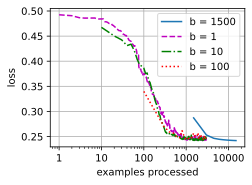

In [11]:
d2l.plot([b * np.arange(1, len(losses) + 1) for b, losses in runs.items()],
         [d2l.numpy(losses) for losses in runs.values()],
         'examples processed', 'loss', legend=[f'b = {b}' for b in runs],
         xscale='log')

An update on $b = 100$ examples takes roughly the same wall-clock time as an update on $b = 1$, making the $b = 100$ epoch nearly $50\text{--}100\times$ faster while tracking the exact same loss curve per example processed. Notice also where linear scaling $\eta \propto b$ breaks down: holding $\eta / b = 0.005$ pushes the learning rate at $b = 100$ to $\eta = 0.5$, where $\eta L = 0.5 \times 2.10 = 1.05$ is no longer small compared to $2$ (inflating the denominator $(2 - \eta\lambda)^{-1}$ in the equation), and any batch size beyond $b \approx 190$ violates the stability ceiling $\eta < 2/L \approx 0.95$. We analyze this critical batch size transition systematically in that section.

## Summary

Minibatch SGD estimates the gradient from $b$ examples, reducing the sampling variance to $\operatorname{tr}(\boldsymbol{\Sigma})/b$ (times $(n-b)/(n-1)$ when sampling without replacement) while amortizing per-step dispatch and memory-bandwidth costs across the minibatch. Under a constant learning rate $\eta$, iterates converge to a stationary **noise ball** whose coordinate variance along curvature $\lambda$ is $\frac{\eta\sigma^2}{b\lambda(2 - \eta\lambda)} \approx \frac{\eta\sigma^2}{2\lambda b}$, widest along the flattest directions. Summing quadratic loss contributions across all modes cancels $\lambda$, leaving an expected stationary **excess loss** of $\mathbb{E}[f(\mathbf{x}_\infty)] - f(\mathbf{x}^\star) \approx \frac{\eta\operatorname{tr}\boldsymbol{\Sigma}(\mathbf{x}^\star)}{4b}$ that vanishes only when the model interpolates every training example at the optimum. Whenever $\eta L \ll 1$, both transient progress per example and the stationary noise floor depend on $\eta$ and $b$ only through their ratio $\eta/b$, until increasing $b$ with $\eta \propto b$ approaches the deterministic curvature ceiling $\eta < 2/L$.

## Exercises

1. **Noise as a random dataset.** Show that `sgd_2d` on $f(\mathbf{x}) = 0.1 x_1^2 + 2x_2^2$ with unit-variance Gaussian gradient noise is equivalent to single-example SGD on $f(\mathbf{x}, \mathbf{w}) = 0.1 (x_1 - w_1)^2 + 2 (x_2 - w_2)^2$ with $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \mathbf{C})$, and determine the covariance $\mathbf{C}$.

1. [code] **The constant of a $1/t$ schedule.** ● For a 1D quadratic of curvature $\lambda$ under gradient noise of variance $\sigma^2$ and learning rate $\eta_t = c / (t + t_0)$:
    1. Write the exact recursion for $e_t = \mathbb{E}[x_t^2]$ and substitute the asymptotic ansatz $e_t \approx A/t$ to show that $A = c^2 \sigma^2 / (2 c \lambda - 1)$ whenever $c > 1/(2\lambda)$. Which value of $c$ minimizes $A$?
    1. Iterate the deterministic recursion for $e_t$ on $\lambda = 0.2, \sigma = 1$ from $e_0 = 25$ with $t_0 = 20$ and $c \in \{1, 2.5, 5, 10\}$ up to $t = 10^6$, plotting $t\,e_t$ versus $t$ on log–log axes, and explain why no single $c$ is simultaneously optimal for both $\lambda_1 = 0.2$ and $\lambda_2 = 4$.

1. [code] **The finite-population factor and reshuffling.**
    1. Let $\mathbf{e}_i = \nabla f_i(\mathbf{x}) - \nabla f(\mathbf{x})$. Using $\sum_{i=1}^n \mathbf{e}_i = \mathbf{0}$, show that $\mathbb{E}_{i \neq j}[\mathbf{e}_i^\top \mathbf{e}_j] = -\operatorname{tr}\boldsymbol{\Sigma}/(n - 1)$ and derive the equation. Verify the formula empirically on the per-example gradients `G` of the airfoil dataset for $b \in \{10, 100, 500, 1000\}$ drawn with and without replacement.
    1. Draw $n = 100$ vectors $\mathbf{w}_i$ from the distribution of Exercise 1 and compare 20-epoch SGD trajectories sampled with replacement versus per-epoch reshuffling at $\eta \in \{0.1, 0.01\}$.

1. [code] **Gradient variance during training.** ●
    1. On the airfoil linear model, compare $\operatorname{tr}\boldsymbol{\Sigma}$ at $\mathbf{w} = \mathbf{0}$ versus $\mathbf{w} = \mathbf{w}^\star$.
    1. Train a two-layer ReLU MLP ($64$ hidden units) on the airfoil data for $10$ epochs ($b = 10, \eta = 0.05$) and compare $\operatorname{tr}\boldsymbol{\Sigma}$ (broken down across `W1`, `b1`, `W2`, `b2`) at initialization versus after training.

1. [code] **Batch size and learning rate scaling.** ● Fix $\eta = 0.05$ at $b = 10$ on the airfoil linear regression model and test $b \in \{1, 10, 100, 1500\}$ under both linear scaling ($\eta \propto b$) and square-root scaling ($\eta \propto \sqrt{b}$). Explain which configurations diverge using $L = 2.10$, and compute the exact stationary excess loss across all $6$ eigenvectors of `H` using the equation to explain why $b = 100, \eta = 0.5$ has a slightly higher floor than $b = 10, \eta = 0.05$.

[Discussions](https://d2l.discourse.group/t/497)